Author: Daniel Abadjiev  
Date: October 27, 2026  
Description: Attempts to explore the edm4hep format and particles inside it.  

In [36]:
import numpy as np
# import pyLCIO
# import ROOT
import uproot
from math import *
import argparse
import os
import random
from plothelper import *
from datetime import datetime
import pandas as pd


file_list = ["./sim_output.edm4hep.root","./sim_output2.edm4hep.root","./sim_output3.edm4hep.root","./digi_real.edm4hep.root"]
filepath = file_list[3]

## Initial uproot exploration

In [ ]:
f = uproot.open(filepath)
print(f.keys())
print(f["events"].keys())
print(f["events"]["VertexBarrelCollection"])
print(f["events"]["VertexBarrelCollection"].keys())
vertexEventsDF = f["events"]["VertexBarrelCollection"].arrays(library="pd")
vertexEventsDF2 = f["events"]["_VertexBarrelCollection_particle"].arrays(library="pd")

outerEventsDF = f["events"]["OuterTrackerBarrelCollection"].arrays(library="pd")
outerEventsDF2 = f["events"]["_OuterTrackerBarrelCollection_particle"].arrays(library="pd")
mcparticles = f["events"]["MCParticles"].arrays(library="pd")
links = f["events"]["VXDBarrelRealHitsRelations"].arrays(library="pd")
linksTo = f["events"]["_VXDBarrelRealHitsRelations_to"].arrays(library="pd")
linksFrom = f["events"]["_VXDBarrelRealHitsRelations_from"].arrays(library="pd")



['configuration_metadata;1', 'events;1', 'metadata;1', 'podio_metadata;1']
['ECalBarrelCollection', 'ECalBarrelCollection/ECalBarrelCollection.cellID', 'ECalBarrelCollection/ECalBarrelCollection.energy', 'ECalBarrelCollection/ECalBarrelCollection.position.x', 'ECalBarrelCollection/ECalBarrelCollection.position.y', 'ECalBarrelCollection/ECalBarrelCollection.position.z', 'ECalBarrelCollection/ECalBarrelCollection.contributions_begin', 'ECalBarrelCollection/ECalBarrelCollection.contributions_end', '_ECalBarrelCollection_contributions', '_ECalBarrelCollection_contributions/_ECalBarrelCollection_contributions.index', '_ECalBarrelCollection_contributions/_ECalBarrelCollection_contributions.collectionID', 'ECalBarrelCollectionContributions', 'ECalBarrelCollectionContributions/ECalBarrelCollectionContributions.PDG', 'ECalBarrelCollectionContributions/ECalBarrelCollectionContributions.energy', 'ECalBarrelCollectionContributions/ECalBarrelCollectionContributions.time', 'ECalBarrelCollectionContr

In [ ]:
def collectionDfFromTree(f: uproot.reading.ReadOnlyDirectory,collectionBranch = "VertexBarrelCollection",collectionBranchIndex="",mcBranch="MCParticles",getMcDf=True):
    assert isinstance(f,uproot.reading.ReadOnlyDirectory)
    assert "events;1" in f.keys()
    if collectionBranchIndex=="":
        collectionBranchIndex = "_"+collectionBranch+"_particle"
    assert collectionBranch in f["events"].keys()
    assert collectionBranchIndex in f["events"].keys()
    assert mcBranch in f["events"].keys()
    df1 = f["events"][collectionBranch].arrays(library="pd")
    df2 = f["events"][collectionBranchIndex].arrays(library="pd")
    eventHitDf = df1.merge(df2,how='outer',left_index=True,right_index=True)
    for idx,row in eventHitDf.iterrows():
        numHits = [len(row[key]) for key in row.keys()]
        assert len(set(numHits)) == 1
    if getMcDf:
        eventMcDf = f["events"][mcBranch].arrays(library="pd")
        assert len(eventHitDf)==len(eventMcDf)
    else:
        eventMcDf=pd.DataFrame()
    return eventHitDf,eventMcDf



In [ ]:
print(type(f))
assert isinstance(f,uproot.reading.ReadOnlyDirectory)
print(f.keys())

<class 'uproot.reading.ReadOnlyDirectory'>
['configuration_metadata;1', 'events;1', 'metadata;1', 'podio_metadata;1']


In [54]:
# vertexEventsDf = vertexEventsDF.merge(vertexEventsDF2,how='outer',left_index=True,right_index=True)
# # print(vertexEventsDf)
# print(vertexEventsDf.keys())
# for idx,row in vertexEventsDf.iterrows():
#     # print(row)
#     numHits = [len(row[key]) for key in row.keys()]
#     assert len(set(numHits)) == 1
vertexEventsDf,mcEventsDf = collectionDfFromTree(f)
print(vertexEventsDf)
print(mcEventsDf)
print(type(mcEventsDf.iloc[0, 0]))
    

                       VertexBarrelCollection.cellID  \
0           [50364417, 50364545, 67141889, 67141889]   
1  [50454529, 50454657, 50446593, 67273217, 67339...   
2              [16867329, 16859137, 16867457, 82177]   
3       [16785409, 16785537, 16785665, 16897, 25345]   
4  [33611777, 33611905, 50389249, 50405889, 50438...   
5  [50446337, 50446465, 50438401, 50487809, 50479...   
6  [33644545, 33644673, 16859393, 16900609, 16941...   
7                     [50372609, 50372737, 67150081]   
8     [16875521, 16875649, 16867585, 123393, 172801]   
9                                                 []   

                         VertexBarrelCollection.eDep  \
0  [1.454484572604997e-05, 1.8365239156992175e-05...   
1  [1.1806205293396488e-05, 1.4764224033569917e-0...   
2  [1.808064007491339e-05, 2.8722470233333297e-05...   
3  [1.5276906196959317e-05, 1.1402589734643698e-0...   
4  [1.3874917385692243e-05, 1.3680019947059918e-0...   
5  [3.3173459087265655e-05, 1.405437069479376e-

In [41]:
hitRows = []
for idx,row in vertexEventsDf.iterrows():
    indexFromKey = "_VertexBarrelCollection_particle.index"
    for ihit in range(len(row[indexFromKey])):
        hitRow = {".".join(key.split(".")[1:]):row[key][ihit] for key in row.keys()}
        # for key in row.keys():
        #     print(".".join(key.split(".")[1:]),row[key][ihit])
        hitRows.append(hitRow)

In [38]:
hitDf = pd.DataFrame(hitRows)
print(hitDf)

      cellID      eDep      time  pathLength     quality  position.x  \
0   50364417  0.000015  0.139147    0.069076           0    0.166005   
1   50364545  0.000018  0.148595    0.069078           0    0.164893   
2   67141889  0.000017  0.237301    0.069423           0    0.076187   
3   67141889  0.000071  0.237606    0.264609  1073741824   -0.204008   
4   50454529  0.000012  0.115823    0.057527           0   28.729155   
5   50454657  0.000015  0.123690    0.057529           0   30.684081   
6   50446593  0.000012  0.196868    0.057683           0   48.879789   
7   67273217  0.000021  0.283859    0.057344           0   70.536461   
8   67339009  0.000015  0.392731    0.057547           0   97.678837   
9   67330817  0.000014  0.393855    0.057847           0   97.959367   
10  16867329  0.000018  0.150477    0.074697           0  -15.072208   
11  16859137  0.000029  0.154760    0.076879           0  -15.500149   
12  16867457  0.000021  0.160692    0.074692           0  -16.09

In [48]:
hitDf.filter(cond=hitDf["index"]==0)

,cellID,eDep,time,pathLength,quality,position.x,position.y,position.z,momentum.x,momentum.y,momentum.z,index,collectionID
0,50364417,0.000015,0.139147,0.069076,0,0.166005,30.165000,28.752296,-0.000333,4.079331,3.888560,0,2714477136
1,50364545,0.000018,0.148595,0.069078,0,0.164893,32.215000,30.706480,-0.003657,4.079118,3.888759,0,2714477136
2,67141889,0.000017,0.237301,0.069423,0,0.076187,51.454839,49.057587,-0.033081,4.076814,3.889820,0,2714477136
3,67141889,0.000071,0.237606,0.264609,1073741824,-0.204008,51.400251,49.047387,-0.000644,-0.000029,0.000198,0,2714477136
4,50454529,0.000012,0.115823,0.057527,0,28.729155,-9.466629,16.986593,7.600472,-2.480031,4.488900,0,2714477136
5,50454657,0.000015,0.123690,0.057529,0,30.684081,-10.103927,18.141061,7.601489,-2.476961,4.488846,0,2714477136
6,50446593,0.000012,0.196868,0.057683,0,48.879789,-16.008125,28.877551,7.609118,-2.454302,4.488136,0,2714477136
7,67273217,0.000021,0.283859,0.057344,0,70.536461,-22.942009,41.643377,7.618674,-2.422507,4.489060,0,2714477136
8,67339009,0.000015,0.392731,0.057547,0,97.678837,-31.491957,57.622644,7.631687,-2.381623,4.488656,0,2714477136
9,67330817,0.000014,0.393855,0.057847,0,97.959367,-31.578543,57.787481,7.631680,-2.381343,4.488688,0,2714477136


In [49]:
mcparticles

,MCParticles.PDG,MCParticles.generatorStatus,MCParticles.simulatorStatus,MCParticles.charge,MCParticles.time,MCParticles.mass,MCParticles.vertex.x,MCParticles.vertex.y,MCParticles.vertex.z,MCParticles.endpoint.x,...,MCParticles.momentum.y,MCParticles.momentum.z,MCParticles.momentumAtEndpoint.x,MCParticles.momentumAtEndpoint.y,MCParticles.momentumAtEndpoint.z,MCParticles.helicity,MCParticles.parents_begin,MCParticles.parents_end,MCParticles.daughters_begin,MCParticles.daughters_end
0,"[13, 11]","[1, 0]","[33554432, 1493172224]","[-1.0, -1.0]","[0.0, 1.5657464265823364]","[0.105658, 0.00051099891]","[0.0, -17.722444167138782]","[-0.0, 338.92905348336257]","[0.0, 323.91187798494366]","[-14978.325317703111, -17.906132151229126]",...,"[4.0794806452784, 0.0006540267347976374]","[3.888636771214501, 0.0011878529580672125]","[-0.6673329853743823, 0.0]","[1.155589501132543, -0.0]","[1.3172816949662964, -0.0]","[9, 0]","[0, 0]","[0, 1]","[0, 1]","[1, 1]"
1,[13],[1],[33554432],[-1.0],[0.0],[0.105658],[-0.0],[-0.0],[0.0],[30000.0],...,[-2.5239134051656444],[4.489886670894518],[4.771205038514525],[-0.4260750582519588],[2.8147974854766526],[9],[0],[0],[0],[0]
2,[13],[1],[33554432],[-1.0],[0.0],[0.105658],[0.0],[-0.0],[0.0],[-9798.580340021712],...,[-14.757168243741107],[-18.608815594535603],[-4.717474018102587],[-12.50867528346515],[-14.679391466158195],[9],[0],[0],[0],[0]
3,[13],[1],[33554432],[-1.0],[0.0],[0.105658],[-0.0],[-0.0],[0.0],[30000.0],...,[13.182194902617882],[-12.472109631249463],[15.754848242228553],[12.85949859357727],[-10.80171609196558],[9],[0],[0],[0],[0]
4,"[13, 11]","[1, 0]","[33554432, 1493172224]","[-1.0, -1.0]","[0.0, 1.9455711841583252]","[0.105658, 0.00051099891]","[0.0, -525.6567825063597]","[-0.0, 182.41339005083833]","[0.0, 174.61382410330472]","[-30000.0, -526.4922562912865]",...,"[4.7603169852149, -0.0004702635582801071]","[4.180302904168899, 0.0017176042339514938]","[-9.429059681113339, 0.0]","[2.2824976651286004, -0.0]","[2.9293642175095207, 0.0]","[9, 0]","[0, 0]","[0, 1]","[0, 1]","[1, 1]"
5,[13],[1],[33554432],[-1.0],[0.0],[0.105658],[0.0],[-0.0],[0.0],[30000.0],...,[-26.68846716864958],[20.55905391190969],[28.266255785460046],[-22.330041335774656],[17.999143975767357],[9],[0],[0],[0],[0]
6,[13],[1],[33554432],[-1.0],[0.0],[0.105658],[-0.0],[-0.0],[0.0],[-6696.100416422737],...,[-9.14273453691781],[-2.721982055158622],[-1.5752976264844518],[-6.813702993624826],[-1.8372281529203094],[9],[0],[0],[0],[0]
7,[13],[1],[33554432],[-1.0],[0.0],[0.105658],[0.0],[-0.0],[0.0],[-19004.549504412942],...,[5.7404457092559475],[7.748353447143966],[-3.069468424246466],[2.479401491093467],[4.77153890895553],[9],[0],[0],[0],[0]
8,[13],[1],[33554432],[-1.0],[0.0],[0.105658],[-0.0],[0.0],[0.0],[5980.025581839189],...,[-4.559888805327136],[-2.400232964602328],[0.3940260909081167],[-2.0848914822255664],[-1.0273188832457505],[9],[0],[0],[0],[0]
9,"[13, 11]","[1, 0]","[33554432, 1493172224]","[-1.0, -1.0]","[0.0, 2.8539845943450928]","[0.105658, 0.00051099891]","[-0.0, 50.79443907343845]","[0.0, 278.3570021890705]","[0.0, -807.459913499898]","[1498.3548563599468, 47.73143152564874]",...,"[29.40303118338428, 0.001353268342212013]","[-85.40694060511805, -0.0006843772144430391]","[4.028643431336815, -0.0]","[28.594129247969434, -0.0]","[-81.84764541783153, -0.0]","[9, 0]","[0, 0]","[0, 1]","[0, 1]","[1, 1]"


In [11]:
print([(mcparticles["MCParticles.PDG"][i])for i in range(10)])

[<Array [13, 11] type='2 * int32'>, <Array [13] type='1 * int32'>, <Array [13] type='1 * int32'>, <Array [13] type='1 * int32'>, <Array [13, 11] type='2 * int32'>, <Array [13] type='1 * int32'>, <Array [13] type='1 * int32'>, <Array [13] type='1 * int32'>, <Array [13] type='1 * int32'>, <Array [13, 11] type='2 * int32'>]


In [13]:
mcparticles.iloc[0]

MCParticles.PDG                                                     [13.0 11.0]
MCParticles.generatorStatus                                           [1.0 0.0]
MCParticles.simulatorStatus                           [33554432.0 1493172224.0]
MCParticles.charge                                                  [-1.0 -1.0]
MCParticles.time                                       [0.0 1.5657464265823364]
MCParticles.mass                                       [0.105658 0.00051099891]
MCParticles.vertex.x                                  [0.0 -17.722444167138782]
MCParticles.vertex.y                                  [-0.0 338.92905348336257]
MCParticles.vertex.z                                   [0.0 323.91187798494366]
MCParticles.endpoint.x                [-14978.325317703111 -17.906132151229126]
MCParticles.endpoint.y                    [26680.43948317624 340.1464476137431]
MCParticles.endpoint.z                              [30000.0 324.5228534862669]
MCParticles.momentum.x              [0.0

In [16]:
vertexEventsDF.iloc[0]

VertexBarrelCollection.cellID            [50364417.0 50364545.0 67141889.0 67141889.0]
VertexBarrelCollection.eDep          [1.454484572604997e-05 1.8365239156992175e-05 ...
VertexBarrelCollection.time          [0.1391465961933136 0.14859545230865479 0.2373...
VertexBarrelCollection.pathLength    [0.06907620280981064 0.06907816231250763 0.069...
VertexBarrelCollection.quality                              [0.0 0.0 0.0 1073741824.0]
VertexBarrelCollection.position.x    [0.16600517596864428 0.16489298773069 0.076186...
VertexBarrelCollection.position.y    [30.165 32.214999999999996 51.45483864807524 5...
VertexBarrelCollection.position.z    [28.75229635761209 30.706479803299622 49.05758...
VertexBarrelCollection.momentum.x    [-0.000332693918608129 -0.003656902117654681 -...
VertexBarrelCollection.momentum.y    [4.079331398010254 4.079117774963379 4.0768136...
VertexBarrelCollection.momentum.z    [3.8885602951049805 3.888758659362793 3.889819...
Name: 0, dtype: awkward

In [15]:
outerEventsDF2.iloc[0]

_OuterTrackerBarrelCollection_particle.index                             [0 0]
_OuterTrackerBarrelCollection_particle.collectionID    [2714477136 2714477136]
Name: 0, dtype: awkward

In [7]:
for b in ["momentum", "momentumAtEndpoint", "endpoint"]:
    print(b, [mcparticles[f"MCParticles.{b}.{c}"][8][0] for c in "xyz"])

momentum [np.float64(-0.4620397954065685), np.float64(-4.559888805327136), np.float64(-2.400232964602328)]
momentumAtEndpoint [np.float64(-0.0), np.float64(-0.0), np.float64(-0.0)]
endpoint [np.float64(-152.6292080241181), np.float64(-1506.3036213638443), np.float64(-792.8876692066572)]


## exploration of saved csvs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
fileStub = "./edmTestFiles/digi_output_mu2.edm4hep.root"
keyNamesToCollections ={"truthParticlesDf":"MCParticles",
                        "vtxBarrelSimHitsDf":"VertexBarrelCollection",
                        "vtxClusterToSimHitDf":"VXDBarrelRealHitsRelations",     
                        "vtxClustersDf":"VXDBarrelRealHits",       
                        "vtxPixelsToClustersDf":"VXDBarrelRealRawHitRelations",
                        "vtxPixelsDf":"VXDBarrelRealPixels",       
                        "truthParticlesDf2":"NewMCParticles",       
                        "vtxBarrelSimHitsDf2":"OverlayVertexBarrelCollection",}
dfDict = {}
convertParquet=False
convertOrc = False #https://towardsdatascience.com/saving-pandas-dataframes-efficiently-and-quickly-parquet-vs-feather-vs-orc-vs-csv-26051cc98f2e/
for key in keyNamesToCollections.keys():
    dfDict[key] = pd.read_csv(f"{fileStub}.{key}.csv")
    if convertParquet:
        dfDict[key].to_parquet(f"{fileStub}.{key}.parquet",compression="zstd")
    if convertOrc:
        dfDict[key].to_orc(f"{fileStub}.{key}.orc") #unable to do compression
        # dfDict[key].to_feather(f"{fileStub}.{key}.feather")


for key in ["vtxClusterSimHitLinksDf","vtxPixelsDfLinked","vtxClustersDfLinked","vtxBarrelSimHitsDf2Linked",]:
    dfDict[key] = pd.read_parquet(f"{fileStub}.{key}.parquet")

In [33]:
dfDict["vtxPixelsDfLinked"]

,cellID,eDep,time,pathLength,quality,position.x,position.y,position.z,momentum.x,momentum.y,momentum.z,particle_index,particle_collectionID,ievent,index,collectionID,secondary,overlay,cluster_row,cluster_index
0,1,4873.566406,0.0,0.0,0,431.0,899.0,0.0,0.0,0.0,0.0,-1,-1,0,0,2056537070,False,False,0,0
1,1,5892.164062,0.0,0.0,0,431.0,900.0,0.0,0.0,0.0,0.0,-1,-1,0,1,2056537070,False,False,0,0
2,1,1738.380737,0.0,0.0,0,432.0,898.0,0.0,0.0,0.0,0.0,-1,-1,0,2,2056537070,False,False,0,0
3,1,1893.164185,0.0,0.0,0,432.0,899.0,0.0,0.0,0.0,0.0,-1,-1,0,3,2056537070,False,False,0,0
4,1,876.803345,0.0,0.0,0,433.0,898.0,0.0,0.0,0.0,0.0,-1,-1,0,4,2056537070,False,False,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6895319,67339009,2271.983398,25.0,0.0,0,6.0,935.0,0.0,0.0,0.0,0.0,-1,-1,1,3212110,2056537070,False,False,807825,390107
6895320,67339009,730.511597,25.0,0.0,0,6.0,936.0,0.0,0.0,0.0,0.0,-1,-1,1,3212111,2056537070,False,False,807825,390107
6895321,67339009,2828.895264,25.0,0.0,0,7.0,931.0,0.0,0.0,0.0,0.0,-1,-1,1,3212112,2056537070,False,False,807825,390107
6895322,67339009,5633.644043,25.0,0.0,0,7.0,932.0,0.0,0.0,0.0,0.0,-1,-1,1,3212113,2056537070,False,False,807825,390107


In [31]:
print(np.unique(dfDict["vtxBarrelSimHitsDf2Linked"]["n_clusters"]))
print(np.unique(dfDict["vtxClustersDfLinked"]["n_signal_sim_hits"]))
print(np.unique(dfDict["vtxClustersDfLinked"]["n_overlay_sim_hits"]))
print(np.unique(dfDict["vtxClustersDfLinked"]["n_sim_hits"]))
print(len(dfDict["vtxClustersDfLinked"].query("n_overlay_sim_hits<1")))
print(len(dfDict["vtxClustersDfLinked"].query("n_overlay_sim_hits>=1")))
print(len(dfDict["vtxClustersDfLinked"].query("n_signal_sim_hits<1")))
print(len(dfDict["vtxClustersDfLinked"].query("n_signal_sim_hits>=1")))
print(len(dfDict["vtxClustersDfLinked"].query("n_overlay_sim_hits>=1 and n_signal_sim_hits>=1")))


[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  16  17  19
  20  22  23  24  26  27  29  32  35  36  37  39  40  41  42  43  44  46
  48  50  51  52  53  54  58  60  61  62  64  65  67  68  69  70  74  75
  76  78  79  80  81  82  83  84  85  86  87  88  89  90  91  92  93  94
  95  96  97  99 101 102 103 104 105 106 107 109 111 112 114 115 116 117
 118 120 121 122 123 127 131 133 134 144 158 160 165 170 172 173 177 178
 183 185 187 190 193 194 195 198 199 204 214 215 216 219 220 221 223 227
 228 229 236 238 239 240 241 242 246 248 255 256 260 263 272 273 278 289
 321 327]
[0 1]
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  23  24  25  28  29  32  34  36  39  43 101 102]
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  23  24  25  28  29  32  34  36  39  43 101 102]
8
807818
807818
8
0


1050847
8
1014860


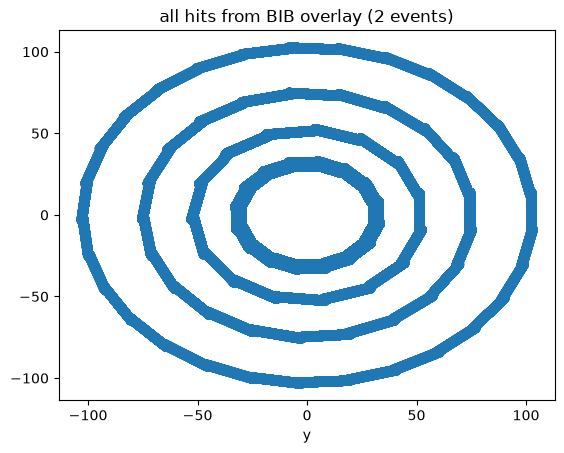

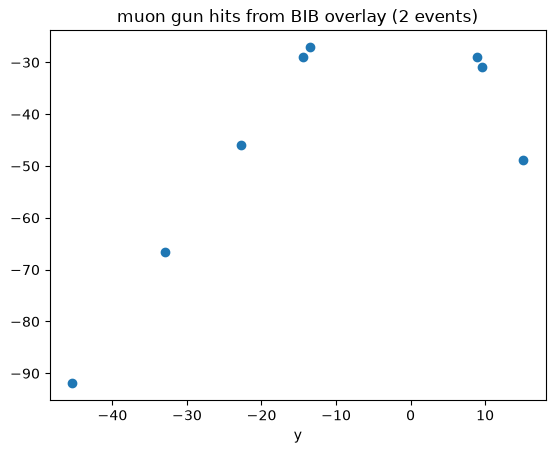

In [7]:
print(len(dfDict["vtxBarrelSimHitsDf2"]))
print(len(dfDict["vtxBarrelSimHitsDf2"].query("particle_collectionID>0")))
print(len(dfDict["vtxBarrelSimHitsDf2"].query("eDep>0.00001")))
plt.scatter(dfDict["vtxBarrelSimHitsDf2"]["position.x"],dfDict["vtxBarrelSimHitsDf2"]["position.y"])
plt.title("all hits from BIB overlay (2 events)")
plt.xlabel("x")
plt.xlabel("y")
plt.show()
plt.scatter(dfDict["vtxBarrelSimHitsDf2"].query("particle_collectionID>0")["position.x"],dfDict["vtxBarrelSimHitsDf2"].query("particle_collectionID>0")["position.y"])
plt.title("muon gun hits from BIB overlay (2 events)")
plt.xlabel("x")
plt.xlabel("y")
plt.show()

In [ ]:
from linkClusters import LinkedClusters
import edm4hepTracksUtils

In [4]:
def unitVector(theta, phi):
    return np.array([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)])

def pixelGlobalPositions(cluster, pixels, pitchMm=0.025):
    u = unitVector(cluster["u.a"], cluster["u.b"]); v = unitVector(cluster["v.a"], cluster["v.b"])
    col, row = pixels["position.x"].to_numpy(float), pixels["position.y"].to_numpy(float)
    w = pixels["eDep"].to_numpy(float)
    c0, r0 = np.average(col, weights=w), np.average(row, weights=w)
    centre = np.array([cluster["position.x"], cluster["position.y"], cluster["position.z"]], float)
    return centre + pitchMm * ((col - c0)[:, None] * u + (row - r0)[:, None] * v)    # N x 3, in mm

# xyz = pixelGlobalPositions(c.cluster, c.pixels)      # c = a LinkedCluster; multiply by 1000 for µm

In [26]:
cl = LinkedClusters.fromFiles(fileStub)

print(len(cl))
print
# print(len(cl.cluster))
print(np.where(cl.nSignal>0))
print(np.where(cl.nSimHits>10))
print(np.unique(cl.clusterTable["cellID"]))
# print(edm4hepTracksUtils.makeDecoder()(np.unique(cl.clusterTable["cellID"])))
print(edm4hepTracksUtils.makeDecoder()(np.unique(cl.clusterTable["cellID"]))["layer"])
print(edm4hepTracksUtils.makeDecoder()(np.unique(cl.clusterTable["cellID"]))["module"])
print(cl.cellFields["layer"])
print(np.unique(cl.cellFields["layer"]))
print(cl.cellFields["module"])
print(np.where(cl.cellFields["layer"]==-1))
print(np.unique(cl.cellFields["module"]))
if True:
    cl=cl[np.where(cl.cellFields["layer"]==0)]
print(np.unique(cl.cellFields["module"]))
justThisModule = 3
if True:
    cl=cl[np.where(cl.cellFields["module"]==justThisModule)]
# print(np.unique(allIds))
# print(np.unique(cl.simHits["cellID"]))
idx=4
print(cl[idx].simHits)
print(cl[idx].simHitRows)
print(cl[idx].nSimHits)
print(cl[idx].nBib)
print(cl[idx].nSignal)
print(cl[idx].pixels)
print(cl[idx].pixelRows)
print(cl[idx].nPixels)
print(cl[idx].cluster)



807826
(array([108955, 225686, 297333, 505390, 606785, 679702, 740346, 794143]),)
(array([  2959,   4277,   4349,   4586,   4626,   4679,   4687,   6609,
        12947,  13278,  18359,  25181,  28486,  29463,  29573,  29584,
        29651,  29658,  29807,  30040,  30218,  37592,  38829,  39131,
        41723,  46371,  53750,  55759,  60139,  67345,  74376,  75004,
        75157,  75190,  75417,  75480,  76664,  76961,  77366,  77460,
        77553,  77988,  79630,  81993,  82972,  84068,  87039,  88114,
        90534,  93123, 104401, 109991, 110005, 110024, 110029, 112128,
       113677, 114754, 114766, 114897, 116258, 128086, 130923, 133134,
       133188, 141366, 161408, 161870, 167318, 172544, 173111, 174295,
       206648, 209225, 209882, 210083, 214468, 214677, 216306, 222280,
       226480, 238543, 239233, 421754, 421793, 421826, 422082, 422121,
       435605, 435772, 435778, 435889, 435906, 444093, 445733, 446341,
       446419, 446456, 455177, 459789, 473382, 474415, 481052, 48

(array([], dtype=int64),)
(array([  851,  5204,  5215,  5281,  5288,  5435,  5667,  5844, 12517,
       13123, 13200, 13237]),)
14814


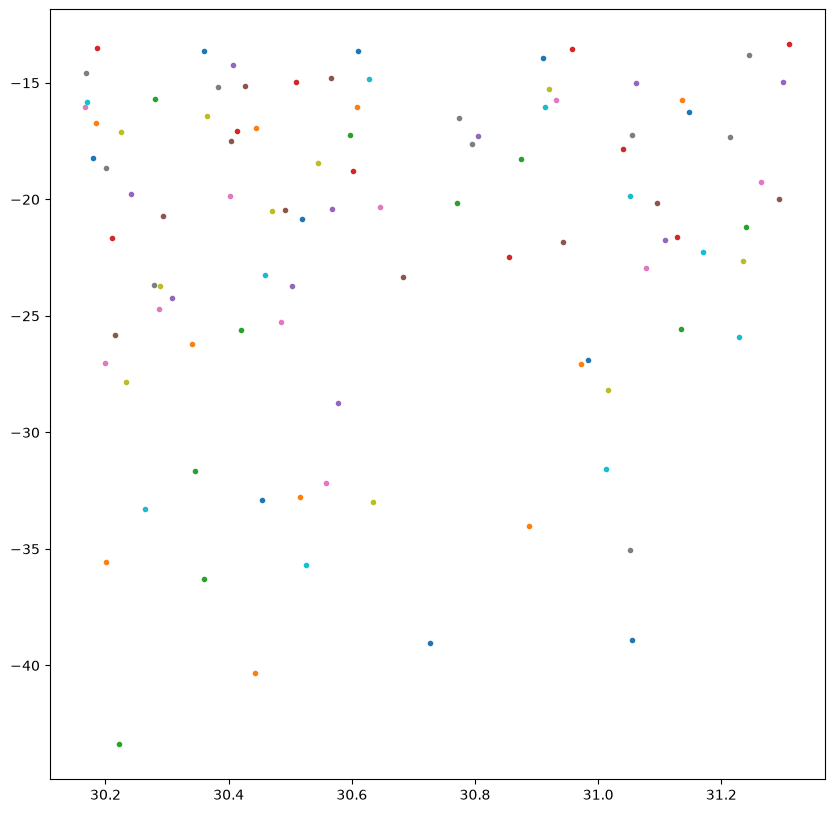

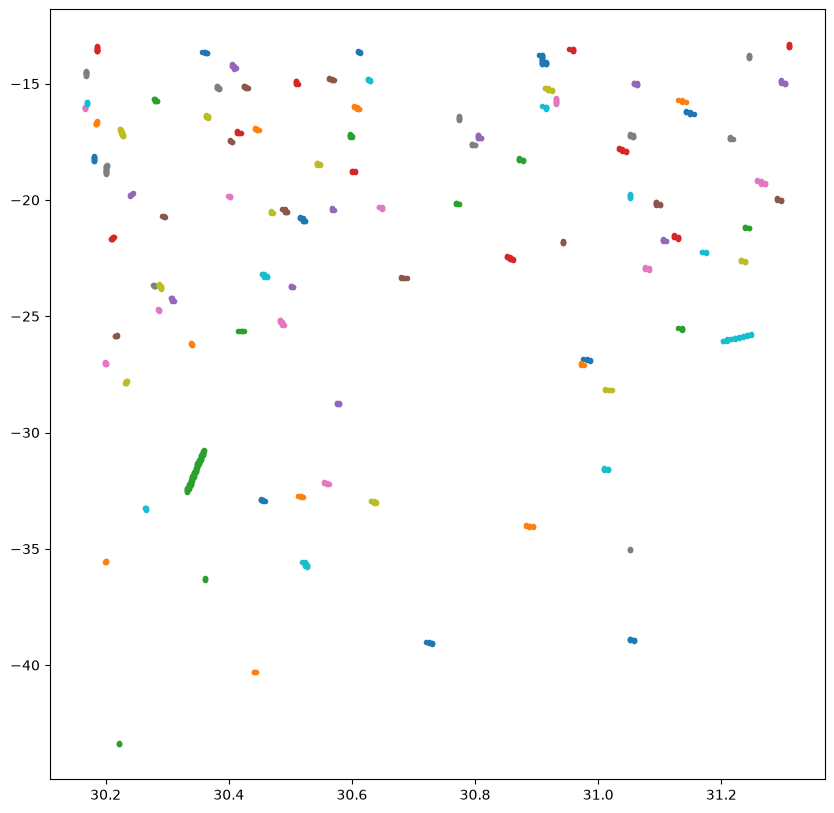

In [36]:
# plt.scatter(cl[idx].pixels["position.x"],cl[idx].pixels["position.y"])
plt.show()
print(np.where(cl.nSignal>0))
print(np.where(cl.nSimHits>10))
print(len(cl))
plt.figure(figsize=(10,10))
for idx in range(100):
    # idx+=106790
    # plt.scatter(cl[idx].pixels["position.x"],cl[idx].pixels["position.y"],marker=".")
    radius = np.sqrt(cl[idx].cluster["position.x"]**2+cl[idx].cluster["position.y"]**2)
    plt.scatter(radius,cl[idx].cluster["position.z"],marker=".")
    # plt.scatter(cl[idx].cluster["position.x"]*1000+cl[idx].pixels["position.x"],cl[idx].cluster["position.y"]*1000+cl[idx].pixels["position.y"],marker=".")
    # print(cl[idx].simHits["cellID"])
    # print(cl[idx].cluster["cellID"])
    # print(edm4hepTracksUtils.makeDecoder()(cl[idx].cluster["cellID"]))
    # print(edm4hepTracksUtils.makeDecoder()(cl[idx].simHits["cellID"]))
    # print(pixelGlobalPositions(cl[idx].cluster,cl[idx].pixels))
plt.show()
plt.figure(figsize=(10,10))
for idx in range(100):
    # idx+=106790
    # plt.scatter(cl[idx].pixels["position.x"],cl[idx].pixels["position.y"],marker=".")
    xyz = pixelGlobalPositions(cl[idx].cluster,cl[idx].pixels)
    # print(xyz)
    r = np.hypot(xyz[:, 0], xyz[:, 1])
    plt.scatter(r, xyz[:, 2], marker=".", label=f"cluster {cl[idx].index}",)
                # color=f"C{idx}") 
plt.show()
